In [4]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/kaggle/input/private-dataset/daily_province.csv")

In [5]:
print(df.shape)
print(df.dtypes)
print(df.head())
print(df.isna().sum())
print(df.duplicated().sum())
print(df.describe().T)


(121092, 6)
date                     object
province                 object
hotspots_snpp             int64
hotspots_noaa20           int64
high_confidence_snpp      int64
frp_sum_snpp            float64
dtype: object
         date            province  hotspots_snpp  hotspots_noaa20  \
0  2012-01-20            Bengkulu              6                0   
1  2012-01-20        Central Java              2                0   
2  2012-01-20  Central Kalimantan              2                0   
3  2012-01-20    Central Sulawesi              8                0   
4  2012-01-20           East Java              2                0   

   high_confidence_snpp  frp_sum_snpp  
0                     0         28.83  
1                     0          4.38  
2                     0          5.65  
3                     0         61.03  
4                     0          2.78  
date                        0
province                    0
hotspots_snpp               0
hotspots_noaa20             0
high_co

In [6]:
df['date'] = pd.to_datetime(df['date'])
print(df["date"].min(), df["date"].max())

print(df.duplicated(subset=["date", "province"]).sum())

n_hari, n_prov = df["date"].nunique(), df["province"].nunique()
print(n_hari, n_prov, n_hari * n_prov, len(df))

print(df.groupby(df["date"].dt.year)[["hotspots_snpp", "hotspots_noaa20"]].sum())

print(df[df["frp_sum_snpp"].isna()]["hotspots_snpp"].value_counts())

5410 34 183940 121092
      hotspots_snpp  hotspots_noaa20
date                                
2012         319942                0
2013         258195                0
2014         554115                0
2015         878049                0
2016         117425                0
2017          91267                0
2018         192498           182372
2019         438278           438252
2020          92197            93944
2021          68533            71299
2022          57352            63985
2023         254542           251469
2024         104523           116542
2025          96292            94699
2026         628295           663233
hotspots_snpp
0    12197
Name: count, dtype: int64


In [7]:
top_provinsi = df.groupby('province')['hotspots_snpp'].sum().reset_index()
top_provinsi = top_provinsi.sort_values(by='hotspots_snpp', ascending=False)

print(top_provinsi.head(10))

              province  hotspots_snpp
6   Central Kalimantan         678910
29     West Kalimantan         462667
25       South Sumatra         441944
21                Riau         397045
20               Papua         321403
10  East Nusa Tenggara         257723
9      East Kalimantan         225457
23    South Kalimantan         165241
13               Jambi         141121
30  West Nusa Tenggara         104684


In [8]:
# 2. Buat kolom baru 'year' dan 'month' dengan mengambil dari kolom 'date'
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# 3. Sekarang filter bulan kemarau (Juli - Oktober) di tahun 2023 sudah bisa dipakai!
df_kemarau_2023 = df[(df['year'] == 2023) & (df['month'].isin([7, 8, 9, 10]))]

print(df_kemarau_2023.head())

            date                 province  hotspots_snpp  hotspots_noaa20  \
91652 2023-07-01  Bangka-Belitung Islands              1                3   
91653 2023-07-01                   Banten              8                4   
91654 2023-07-01             Central Java             10                8   
91655 2023-07-01       Central Kalimantan              1                1   
91656 2023-07-01         Central Sulawesi              5               15   

       high_confidence_snpp  frp_sum_snpp  year  month  
91652                     0          2.51  2023      7  
91653                     0         22.62  2023      7  
91654                     0         32.58  2023      7  
91655                     0          3.45  2023      7  
91656                     0         14.94  2023      7  


In [9]:
# 1. Filter khusus bulan Juli 2023
juli_2023 = df[(df['year'] == 2023) & (df['month'] == 7)]

# 2. Groupby berdasarkan provinsi, lalu jumlahkan total hotspots_snpp-nya
rekap_juli = juli_2023.groupby('province')['hotspots_snpp'].sum().reset_index()

# 3. Urutkan dari yang terbanyak
rekap_juli = rekap_juli.sort_values(by='hotspots_snpp', ascending=False)

print(rekap_juli.head(10))

              province  hotspots_snpp
29     West Kalimantan           5111
8            East Java           1248
10  East Nusa Tenggara            947
23    South Kalimantan            768
9      East Kalimantan            648
20               Papua            648
30  West Nusa Tenggara            467
5         Central Java            460
6   Central Kalimantan            343
24      South Sulawesi            281


/tmp/ipykernel_49/2779427109.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hotspots_snpp', y='province', data=top_10, palette='Reds_r')


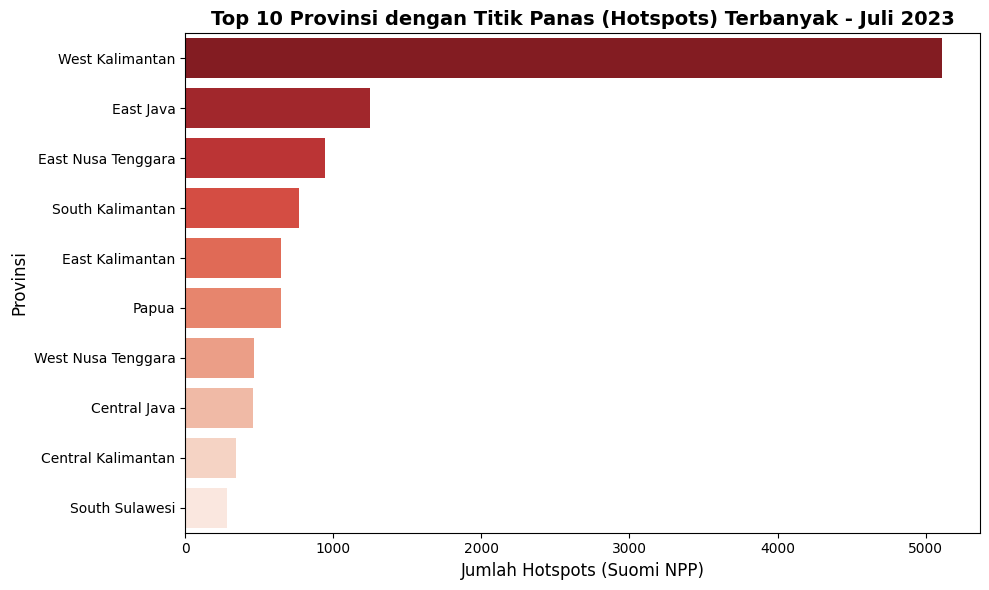

In [10]:
top_10 = rekap_juli.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(x='hotspots_snpp', y='province', data=top_10, palette='Reds_r')

plt.title('Top 10 Provinsi dengan Titik Panas (Hotspots) Terbanyak - Juli 2023', fontsize=14, fontweight='bold')
plt.xlabel('Jumlah Hotspots (Suomi NPP)', fontsize=12)
plt.ylabel('Provinsi', fontsize=12)

plt.tight_layout()
plt.show()

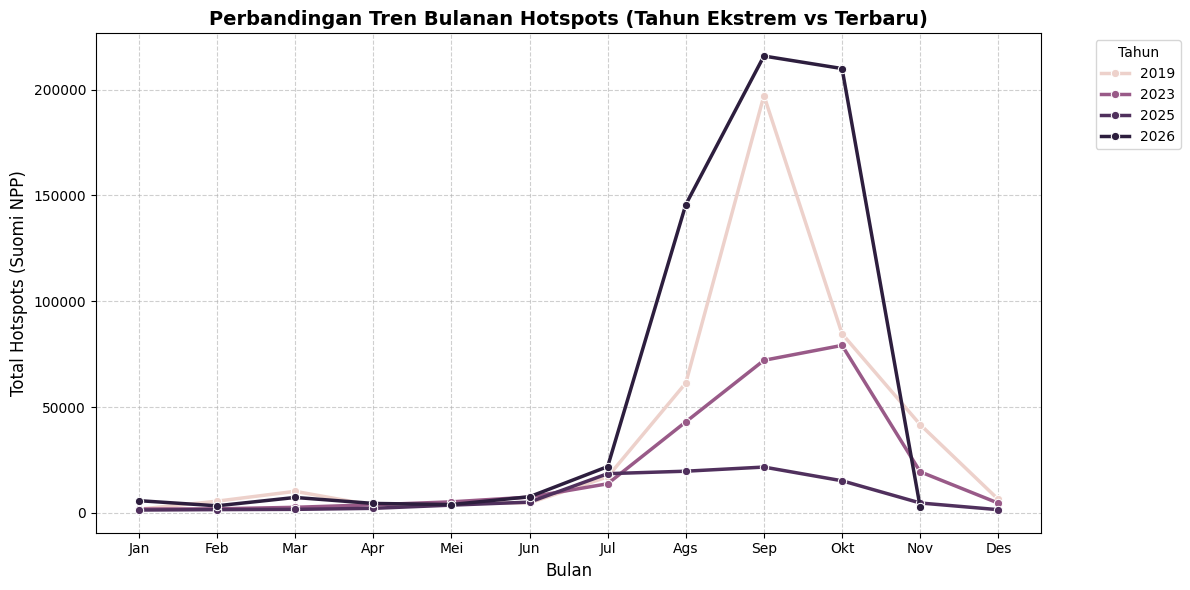

In [11]:
tren_bulanan = df.groupby(["year", 'month'])["hotspots_snpp"].sum().reset_index()
tahun_fokus = [2019, 2023, 2025, 2026]
df_fokus = tren_bulanan[tren_bulanan["year"].isin(tahun_fokus)]

plt.figure(figsize=(12,6))
sns.lineplot(
    data=df_fokus,
    x="month",
    y="hotspots_snpp",
    hue="year",
    marker="o",
    linewidth=2.5
)

plt.title('Perbandingan Tren Bulanan Hotspots (Tahun Ekstrem vs Terbaru)', fontsize=14, fontweight='bold')
plt.xlabel('Bulan', fontsize=12)
plt.ylabel('Total Hotspots (Suomi NPP)', fontsize=12)

# Mengubah angka bulan (1-12) menjadi nama singkatan bulan
plt.xticks(
    range(1, 13), 
    ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Ags', 'Sep', 'Okt', 'Nov', 'Des']
)

plt.legend(title='Tahun', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [12]:
# df.to_csv('clean_fs_indo.csv', index=False)